# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [3]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

    Country  Region  Year  CO2_Mt  CO2_per_capita
275  Russia  Europe  2022  1323.1            1.12
2022


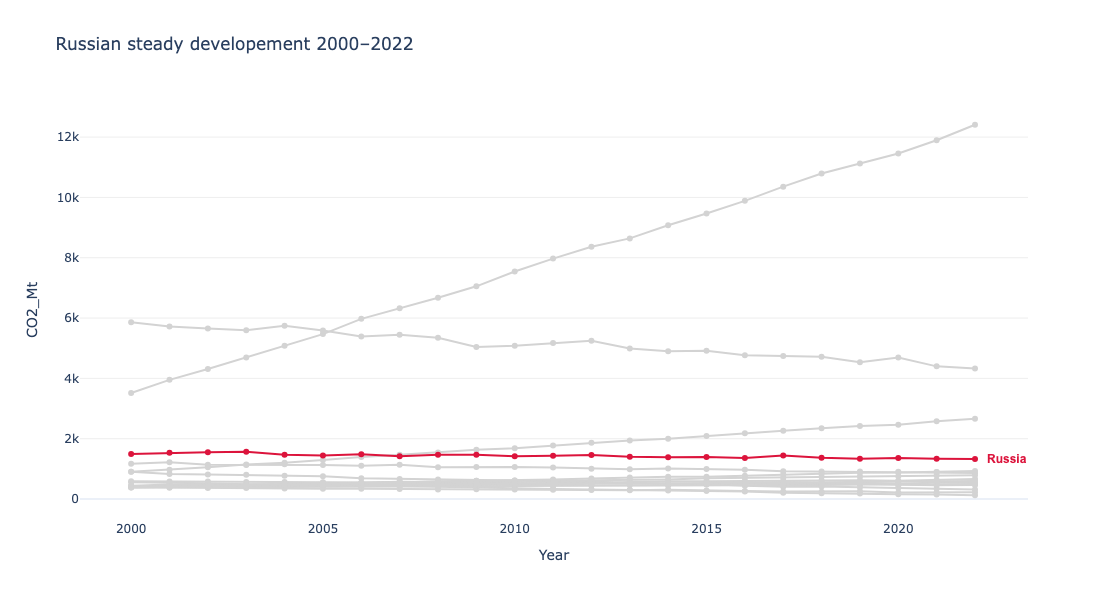

In [82]:
color_map = {c: 'crimson' if c == 'Russia' else 'lightgrey' for c in df['Country'].unique()}

fig = px.line(
    df,
    x='Year',
    y='CO2_Mt',
    color='Country',
    color_discrete_map=color_map,
    title='Russian steady developement 2000–2022',
    markers=True,
    template='plotly_white',
    height=600
)

fig.update_layout(
    yaxis=dict(gridcolor='#EEEEEE'),
    xaxis=dict(showgrid=False)
)

last_yr = df.loc[(df['Year'] == df['Year'].max()) & (df['Country'] == 'Russia')]
print(last_yr.head())
for i, row in last_yr.iterrows():
    print(row['Year'])
    fig.add_annotation(
        x=row['Year'],
        y=row['CO2_Mt'],
        text=row['Country'],
        showarrow=False,
        xanchor='left',
        xshift=10,
        font=dict(color='crimson', size=12, weight='bold', family='Arial')
    )

fig.update_traces(
    showlegend=False
)

fig.show()

---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

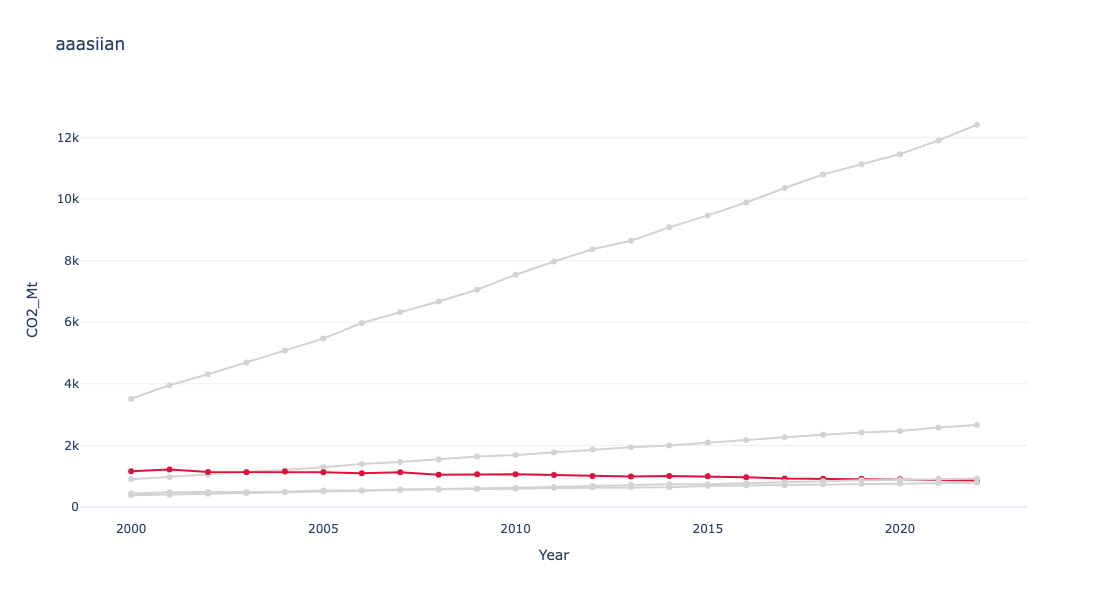

In [87]:
color_map = {c: 'crimson' if c == 'Japan' else 'lightgrey' for c in df['Country'].unique()}

asian_df = df.loc[(df['Region'] == 'Asia')]

fig = px.line(
    asian_df,
    x='Year',
    y='CO2_Mt',
    color='Country',
    color_discrete_map=color_map,
    title='Green or stagnat? The only Asi',
    markers=True,
    template='plotly_white',
    height=600
)

fig.update_layout(
    yaxis=dict(gridcolor='#EEEEEE'),
    xaxis=dict(showgrid=False)
)

# last_yr = df.loc[(df['Year'] == df['Year'].max()) & (df['Country'] == 'Russia')]
# print(last_yr.head())
# for i, row in last_yr.iterrows():
#     print(row['Year'])
#     fig.add_annotation(
#         x=row['Year'],
#         y=row['CO2_Mt'],
#         text=row['Country'],
#         showarrow=False,
#         xanchor='left',
#         xshift=10,
#         font=dict(color='crimson', size=12, weight='bold', family='Arial')
#     )

fig.update_traces(
    showlegend=False
)

fig.show()